<a href="https://colab.research.google.com/github/nerminecheriaa/beam-prediction-deepsense6g/blob/main/notebooks/B_radar_fusion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Cellule 1 : installation

In [5]:
from google.colab import drive; drive.mount('/content/drive')
!mkdir -p /content/data /content/drive/MyDrive/beam_data_B
!unzip -q -n /content/drive/MyDrive/beam_data/scenario32.zip -d /content/data
%cd /content
!rm -rf /content/repo
!git clone -q https://github.com/nerminecheriaa/beam-prediction-deepsense6g.git /content/repo
%cd /content/repo
import sys; sys.path.insert(0, "/content/repo")

Mounted at /content/drive
/content
/content/repo


Cellule 2 : données

In [6]:
import os, torch, numpy as np, pandas as pd
from src.evaluate import topk_accuracy
from src.radar_models import RadarCNN, FusionNet, late_fusion
from src.train_radar import fit, predict
dev = "cuda" if torch.cuda.is_available() else "cpu"
print("device :", dev)
B_DIR = "/content/drive/MyDrive/beam_data_B"
CAM_DIR = "/content/drive/MyDrive/beam_data/camera/seeds_final"
SEEDS = [0, 1, 2, 3, 4]

df = pd.read_csv("splits.csv")
y = torch.tensor(df.beam_label.values)
tr, va, te = [torch.tensor((df.split == s).values) for s in ("train", "val", "test")]
npy = f"{B_DIR}/radar_maps_dop.npy"
if not os.path.exists(npy):
    from src.radar import build_radar_cache
    build_radar_cache(df, "/content/data", npy, method="doppler")   # ~7 min
X = torch.from_numpy(np.load(npy))
sub = lambda m: (X[m], y[m])
print(X.shape, X.dtype)

def load_cam(s):
    co = torch.load(f"{CAM_DIR}/camera_outputs_seed{s}.pt", weights_only=False)
    for sp, m in (("train", tr), ("val", va), ("test", te)):
        assert (df["index"].values[m.numpy()] == co[sp]["index"].numpy()).all(), sp
    return co
cams = {s: load_cam(s) for s in SEEDS}
print("alignement caméra OK")

device : cuda
torch.Size([3235, 1, 64, 256]) torch.float16
alignement caméra OK


Cellule 3 (B1) : radar sur 5 graines

In [7]:
import torch
print(torch.__version__, "| GPU dispo :", torch.cuda.is_available())
!nvidia-smi | head -12

2.14.1+cu130 | GPU dispo : True
Sat Nov  7 19:09:38 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   40C    P8             11W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+---------------

In [8]:
os.makedirs(f"{B_DIR}/radar_seeds", exist_ok=True)
rad = {}
for s in SEEDS:
    p = f"{B_DIR}/radar_seeds/radar_logits_seed{s}.pt"
    if os.path.exists(p):
        rad[s] = torch.load(p, weights_only=False); continue
    torch.manual_seed(s); np.random.seed(s)
    r = fit(RadarCNN(), sub(tr), sub(va), epochs=20, lr=5e-4, device=dev)
    rad[s] = {"val": predict(r, sub(va), dev), "test": predict(r, sub(te), dev), "seed": s}
    torch.save(rad[s], p)
    print(f"graine {s} radar test :", topk_accuracy(rad[s]["test"], y[te]))

epoch 01  loss 3.467  val top1 0.157  top3 0.267
epoch 02  loss 3.269  val top1 0.157  top3 0.271
epoch 03  loss 3.738  val top1 0.157  top3 0.267
epoch 04  loss 3.137  val top1 0.151  top3 0.273
epoch 05  loss 3.468  val top1 0.153  top3 0.271
epoch 06  loss 3.482  val top1 0.155  top3 0.265
epoch 07  loss 3.441  val top1 0.151  top3 0.269
epoch 08  loss 3.384  val top1 0.151  top3 0.276
epoch 09  loss 3.294  val top1 0.149  top3 0.263
epoch 10  loss 3.155  val top1 0.157  top3 0.271
epoch 11  loss 3.193  val top1 0.153  top3 0.269
epoch 12  loss 3.292  val top1 0.149  top3 0.267
epoch 13  loss 3.668  val top1 0.155  top3 0.280
epoch 14  loss 3.161  val top1 0.155  top3 0.276
epoch 15  loss 3.442  val top1 0.141  top3 0.267
epoch 16  loss 3.372  val top1 0.155  top3 0.280
epoch 17  loss 2.998  val top1 0.145  top3 0.284
epoch 18  loss 3.747  val top1 0.157  top3 0.280
epoch 19  loss 3.345  val top1 0.155  top3 0.271
epoch 20  loss 3.448  val top1 0.153  top3 0.273
graine 0 radar test 

Cellule 4 (B3) : fusion tardive sur 5 graines


In [9]:
yv, yt = y[va], y[te]
late, wsel = {}, {}
for s in SEEDS:
    cv, ct = cams[s]["val"]["logits"], cams[s]["test"]["logits"]
    rv, rt = rad[s]["val"], rad[s]["test"]
    score = lambda w: sum(topk_accuracy(late_fusion(cv, rv, w), yv).values())
    wsel[s] = float(max(np.arange(0, 1.01, 0.1), key=score))     # choisi sur la VALIDATION
    late[s] = late_fusion(ct, rt, wsel[s])
print("w_cam par graine :", wsel)

w_cam par graine : {0: 0.7000000000000001, 1: 0.7000000000000001, 2: 0.7000000000000001, 3: 0.8, 4: 0.7000000000000001}


Cellule 5 (B4) : fusion par concaténation, 5 graines (on garde les logits)


In [10]:
from src.dataset import build_image_cache, get_split
from src.models import CameraResNet18
from src.train import predict as cam_predict, set_seed
cache = build_image_cache("/content/repo/splits.csv", "/content/data",
                          "/content/drive/MyDrive/beam_data/camera/cam_cache_224.pt")
set_seed(0)
base = CameraResNet18(pretrained=True).to(dev)        # ResNet18 ImageNet NON affiné
feats = {sp: cam_predict(base, get_split(cache, sp)[0], dev, return_features=True)[1]
         for sp in ("train", "val", "test")}
concat = {}
for s in SEEDS:
    torch.manual_seed(s); np.random.seed(s)
    f = fit(FusionNet(RadarCNN()), (feats["train"], X[tr], y[tr]), (feats["val"], X[va], yv),
            epochs=20, lr=5e-4, device=dev)
    concat[s] = predict(f, (feats["test"], X[te], yt), dev)

Cache rechargé depuis /content/drive/MyDrive/beam_data/camera/cam_cache_224.pt : (3235, 3, 224, 224)
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 162MB/s]


epoch 01  loss 3.688  val top1 0.131  top3 0.278
epoch 02  loss 3.530  val top1 0.157  top3 0.282
epoch 03  loss 3.448  val top1 0.157  top3 0.288
epoch 04  loss 3.238  val top1 0.122  top3 0.269
epoch 05  loss 2.912  val top1 0.092  top3 0.229
epoch 06  loss 3.570  val top1 0.137  top3 0.257
epoch 07  loss 2.927  val top1 0.116  top3 0.261
epoch 08  loss 2.983  val top1 0.143  top3 0.276
epoch 09  loss 2.902  val top1 0.122  top3 0.253
epoch 10  loss 2.961  val top1 0.141  top3 0.269
epoch 11  loss 3.047  val top1 0.059  top3 0.176
epoch 12  loss 2.945  val top1 0.145  top3 0.263
epoch 13  loss 2.762  val top1 0.061  top3 0.171
epoch 14  loss 3.164  val top1 0.061  top3 0.204
epoch 15  loss 2.411  val top1 0.149  top3 0.294
epoch 16  loss 2.719  val top1 0.116  top3 0.276
epoch 17  loss 2.778  val top1 0.090  top3 0.239
epoch 18  loss 2.950  val top1 0.059  top3 0.176
epoch 19  loss 2.498  val top1 0.053  top3 0.151
epoch 20  loss 2.844  val top1 0.041  top3 0.139
epoch 01  loss 3.693

Cellule 6 : tableau final (moyenne ± écart-type, K pour 50 %)

In [11]:
def kcurve(lo, yy):                      # Top-K pour K = 1..64
    rk = (lo > lo.gather(1, yy.view(-1, 1))).sum(1)         # rang du vrai faisceau
    return torch.stack([(rk < k).float().mean() for k in range(1, 65)]).numpy() * 100
k50 = lambda c: int(np.argmax(c >= 50)) + 1 if (c >= 50).any() else 65

counts = torch.bincount(y[tr], minlength=64).float().expand(int(te.sum()), 64)
methods = {
    "Fréquence (plancher)": {s: counts for s in SEEDS},
    "Caméra (finale aug_soft)": {s: cams[s]["test"]["logits"] for s in SEEDS},
    "Radar seul": {s: rad[s]["test"] for s in SEEDS},
    "Fusion concaténation": concat,
    "Fusion tardive": late,
}
rows, curves = [], {}
for name, d in methods.items():
    C = np.stack([kcurve(d[s], yt) for s in SEEDS]); curves[name] = C
    row = {"Méthode": name}
    for k in (1, 3, 5):
        row[f"Top-{k}"] = f"{C[:, k-1].mean():.1f} ± {C[:, k-1].std(ddof=1):.1f}"
    ks = [k50(c) for c in C]
    row["K pour 50 %"] = f"{np.mean(ks):.1f}"
    row["Gain d'overhead à K50"] = f"{100 * (1 - np.mean(ks) / 64):.1f} %"
    rows.append(row)
res = pd.DataFrame(rows); print(res.to_string(index=False))
res.to_csv(f"{B_DIR}/resultats_final.csv", index=False)

                 Méthode      Top-1      Top-3      Top-5 K pour 50 % Gain d'overhead à K50
    Fréquence (plancher) 13.1 ± 0.0 36.2 ± 0.0 42.3 ± 0.0         9.0                85.9 %
Caméra (finale aug_soft) 16.2 ± 3.0 38.0 ± 2.5 49.2 ± 2.3         5.8                90.9 %
              Radar seul 17.0 ± 1.9 34.8 ± 1.9 43.3 ± 0.4         8.6                86.6 %
    Fusion concaténation 13.7 ± 3.3 32.1 ± 6.0 39.8 ± 5.3         9.2                85.6 %
          Fusion tardive 17.7 ± 3.6 41.9 ± 3.5 56.0 ± 4.6         4.8                92.5 %


Cellule 7 : courbe Top-K moyenne


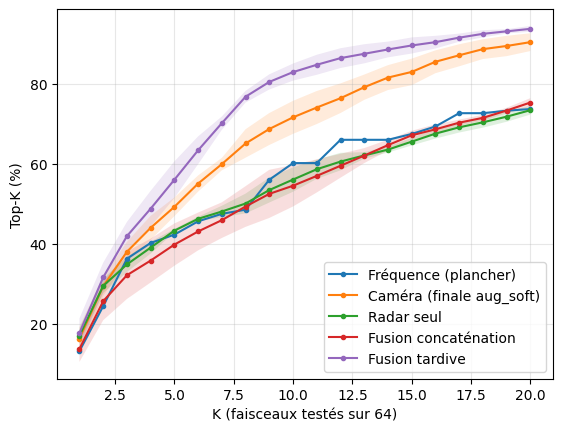

In [12]:
import matplotlib.pyplot as plt
for name, C in curves.items():
    m, sd = C[:, :20].mean(0), C[:, :20].std(0, ddof=1)
    plt.plot(range(1, 21), m, label=name, marker="o", ms=3)
    plt.fill_between(range(1, 21), m - sd, m + sd, alpha=.15)
plt.xlabel("K (faisceaux testés sur 64)"); plt.ylabel("Top-K (%)"); plt.legend(); plt.grid(alpha=.3)
plt.savefig(f"{B_DIR}/topk_curves_final.png", dpi=200, bbox_inches="tight"); plt.show()